In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
base = '/content/drive/MyDrive/dragon-babies'
for d in ['data/raw', 'data/clean', 'fig', 'notes']:
    os.makedirs(f'{base}/{d}', exist_ok=True)

import pandas, matplotlib, openpyxl
print(pandas.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
2.2.3


In [4]:
import pandas as pd

for f in ['monthly/縣市出生死亡結婚離婚(按登記)-113年.xls',
          '縣市出生按生母五齡組(按發生)(96).xls']:
    xls = pd.ExcelFile(f'{base}/data/raw/{f}')
    print(f, '→', xls.sheet_names)

monthly/縣市出生死亡結婚離婚(按登記)-113年.xls → ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '01-12累計', '縣市全年出生率、結婚率等']
縣市出生按生母五齡組(按發生)(96).xls → ['114', '113', '112', '111', '110', '109', '108', '107', '106', '105', '104', '103', '102', '101', '100', '99', '98', '97', '96']


In [6]:
def read_month(path, sheet):
    df = pd.read_excel(path, sheet_name=sheet, header=None,
                       skiprows=5, usecols=[0, 1, 2])
    df.columns = ['county', 'sex', 'births']
    df['county'] = df['county'].bfill()
    for c in ['county', 'sex']:
        df[c] = df[c].astype(str).str.replace(r'\s+', '', regex=True)
    return df[df['sex'] == '計']

a = read_month(m + '縣市出生死亡結婚離婚(按登記)-113年.xls', '12')
b = read_month(m + '縣市出生死亡結婚離婚(按登記)-100年.xls', '10012')
print(a.head(8), '\n', b.head(8))

   county sex   births
0      總計   計  12496.0
3     新北市   計   1573.0
6     臺北市   計   1583.0
9     桃園市   計   1590.0
12    臺中市   計   1410.0
15    臺南市   計    877.0
18    高雄市   計   1490.0
21    臺灣省   計   3910.0 
    county sex   births
0      總計   計  18703.0
3     新北市   計   3445.0
6     臺北市   計   2410.0
9     臺中市   計   2322.0
12    臺南市   計   1367.0
15    高雄市   計   2038.0
18    臺灣省   計   7006.0
21    宜蘭縣   計    317.0


In [7]:
import glob, re

rows = []
for path in sorted(glob.glob(m + '*.xls')):
    roc = int(re.search(r'-(\d+)年', path).group(1))
    for sh in pd.ExcelFile(path).sheet_names:
        if not sh.isdigit():
            continue
        df = read_month(path, sh)
        df['date'] = pd.Timestamp(roc + 1911, int(sh[-2:]), 1)
        rows.append(df)

births = pd.concat(rows, ignore_index=True)
births['births'] = pd.to_numeric(births['births'], errors='coerce').fillna(0).astype(int)
births['county'] = births['county'].replace({'桃園縣': '桃園市', '總計': '全國'})
births = births[~births['county'].isin(['臺灣省', '福建省'])][['date', 'county', 'births']]

print(births.shape, births['date'].min(), births['date'].max())
print(births['county'].value_counts())

(4370, 3) 2011-01-01 00:00:00 2026-10-01 00:00:00
county
全國     190
新北市    190
臺北市    190
臺中市    190
臺南市    190
高雄市    190
宜蘭縣    190
桃園市    190
新竹縣    190
苗栗縣    190
彰化縣    190
南投縣    190
雲林縣    190
嘉義縣    190
屏東縣    190
臺東縣    190
花蓮縣    190
澎湖縣    190
基隆市    190
新竹市    190
嘉義市    190
金門縣    190
連江縣    190
Name: count, dtype: int64


In [8]:
nat = births[births['county'] == '全國'].set_index('date')['births']
cty = births[births['county'] != '全國'].groupby('date')['births'].sum()
print('縣市加總與全國的最大差距：', (cty - nat).abs().max())

print(nat.groupby(nat.index.year).sum())

births.to_csv(f'{base}/data/clean/monthly_births.csv', index=False)

縣市加總與全國的最大差距： 0
date
2011    196627
2012    229481
2013    199113
2014    210383
2015    213598
2016    208440
2017    193844
2018    181601
2019    177767
2020    165249
2021    153820
2022    138986
2023    135571
2024    134856
2025    107812
2026     77481
Name: births, dtype: int64


In [9]:
f_ann = f'{base}/data/raw/縣市出生按生母五齡組(按發生)(96).xls'
merge = {'臺北縣': '新北市', '臺中縣': '臺中市', '臺南縣': '臺南市',
         '高雄縣': '高雄市', '桃園縣': '桃園市', '總計': '全國'}
keep = set(births['county'])

rows = []
for sh in pd.ExcelFile(f_ann).sheet_names:
    df = pd.read_excel(f_ann, sheet_name=sh, header=None, usecols=[0, 1])
    df.columns = ['county', 'births']
    df['county'] = df['county'].astype(str).str.replace(r'\s+', '', regex=True).replace(merge)
    df = df[df['county'].isin(keep)].copy()
    df['year'] = int(sh) + 1911
    rows.append(df)

annual = pd.concat(rows)
annual['births'] = pd.to_numeric(annual['births'], errors='coerce')
annual = annual.groupby(['year', 'county'], as_index=False)['births'].sum()

print(annual.groupby('year')['county'].count().unique())
print(annual[annual['county'] == '全國'])

[23]
     year county  births
0    2007     全國  203711
23   2008     全國  196486
46   2009     全國  192133
69   2010     全國  166473
92   2011     全國  198348
115  2012     全國  234599
138  2013     全國  194939
161  2014     全國  211399
184  2015     全國  213093
207  2016     全國  207600
230  2017     全國  194616
253  2018     全國  180656
276  2019     全國  175074
299  2020     全國  161288
322  2021     全國  157019
345  2022     全國  137413
368  2023     全國  133895
391  2024     全國  134769
414  2025     全國  105676


In [10]:
nat_a = annual[annual['county'] == '全國'].set_index('year')['births']
cty_a = annual[annual['county'] != '全國'].groupby('year')['births'].sum()
print('縣市加總與全國的最大差距：', (cty_a - nat_a).abs().max())
annual.to_csv(f'{base}/data/clean/annual_births.csv', index=False)

tbl = annual[annual['county'].isin(['全國', '臺南市'])].pivot(
    index='year', columns='county', values='births')
yoy = tbl.pct_change().mul(100).round(1).add_suffix('_年增%')
print(pd.concat([tbl, yoy], axis=1))

縣市加總與全國的最大差距： 0
county      全國    臺南市  全國_年增%  臺南市_年增%
year                                  
2007    203711  15195     NaN      NaN
2008    196486  14688    -3.5     -3.3
2009    192133  14232    -2.2     -3.1
2010    166473  11657   -13.4    -18.1
2011    198348  14340    19.1     23.0
2012    234599  18030    18.3     25.7
2013    194939  14479   -16.9    -19.7
2014    211399  15526     8.4      7.2
2015    213093  15757     0.8      1.5
2016    207600  14630    -2.6     -7.2
2017    194616  13914    -6.3     -4.9
2018    180656  12275    -7.2    -11.8
2019    175074  11711    -3.1     -4.6
2020    161288  10489    -7.9    -10.4
2021    157019   9895    -2.6     -5.7
2022    137413   8870   -12.5    -10.4
2023    133895   9241    -2.6      4.2
2024    134769   9091     0.7     -1.6
2025    105676   7032   -21.6    -22.6


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(4370, 3) (437, 3)


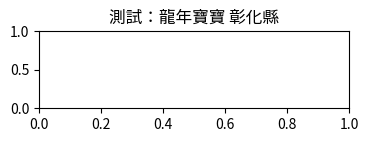

In [2]:
!apt-get -qq install fonts-noto-cjk > /dev/null

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

for w in ['Regular', 'Bold']:
    fm.fontManager.addfont(f'/usr/share/fonts/opentype/noto/NotoSansCJK-{w}.ttc')
plt.rcParams['font.family'] = 'Noto Sans CJK JP'

base = '/content/drive/MyDrive/dragon-babies'
monthly = pd.read_csv(f'{base}/data/clean/monthly_births.csv', parse_dates=['date'])
annual = pd.read_csv(f'{base}/data/clean/annual_births.csv')
print(monthly.shape, annual.shape)

fig, ax = plt.subplots(figsize=(4, 1))
ax.set_title('測試：龍年寶寶 彰化縣')
plt.show()

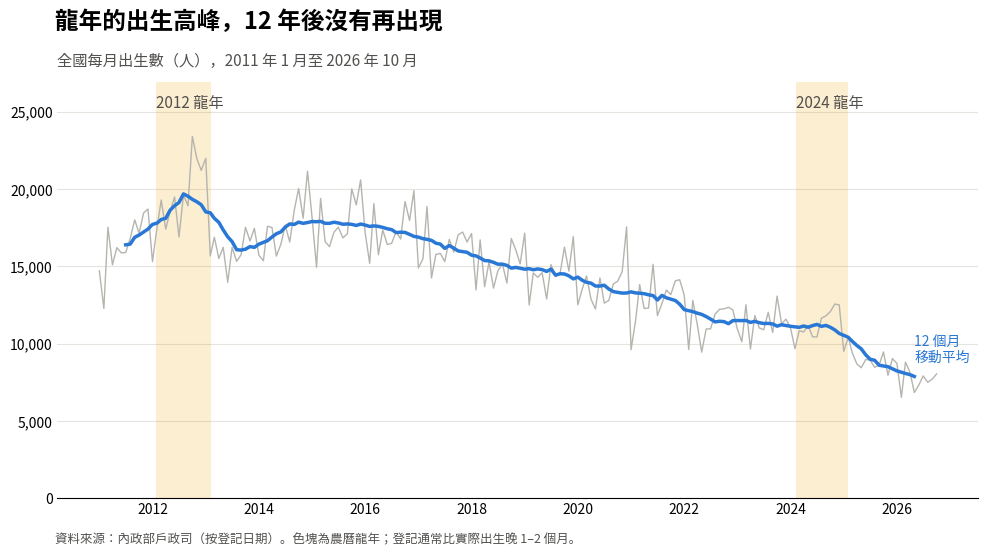

In [10]:
from matplotlib.ticker import FuncFormatter

nat = monthly[monthly['county'] == '全國'].set_index('date')['births']
ma = nat.rolling(12, center=True).mean()
top = nat.max() * 1.15

fig, ax = plt.subplots(figsize=(10, 5.5))
for s, e, lab in [('2012-01-23', '2013-02-09', '2012 龍年'),
                  ('2024-02-10', '2025-01-28', '2024 龍年')]:
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color='#eda100', alpha=0.18, lw=0)
    ax.text(pd.Timestamp(s), top * 0.94, lab, fontsize=11, color='#52514e')

ax.plot(nat.index, nat, color='#b5b4ae', lw=1)
ax.plot(ma.index, ma, color='#2a78d6', lw=2.5)
ax.text(ma.dropna().index[-1], ma.dropna().iloc[-1] * 1.12, '12 個月\n移動平均',
        color='#2a78d6', fontsize=10)

ax.set_ylim(0, top)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.grid(axis='y', color='#e5e4df', lw=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)

fig.suptitle('龍年的出生高峰，12 年後沒有再出現', x=0.06, ha='left',
             fontsize=17, fontweight='bold')
ax.set_title('全國每月出生數（人），2011 年 1 月至 2026 年 10 月', loc='left',
             fontsize=11, color='#52514e', pad=12)
fig.text(0.06, 0.01, '資料來源：內政部戶政司（按登記日期）。色塊為農曆龍年；登記通常比實際出生晚 1–2 個月。',
         fontsize=9, color='#52514e')
fig.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(f'{base}/fig/01-main.png', dpi=200)
plt.show()

county    全國   彰化縣
year              
2011    19.1  12.7
2012    18.3  17.8
2013   -16.9 -19.9
2023    -2.6  -2.8
2024     0.7  -8.3
2025   -21.6 -25.6


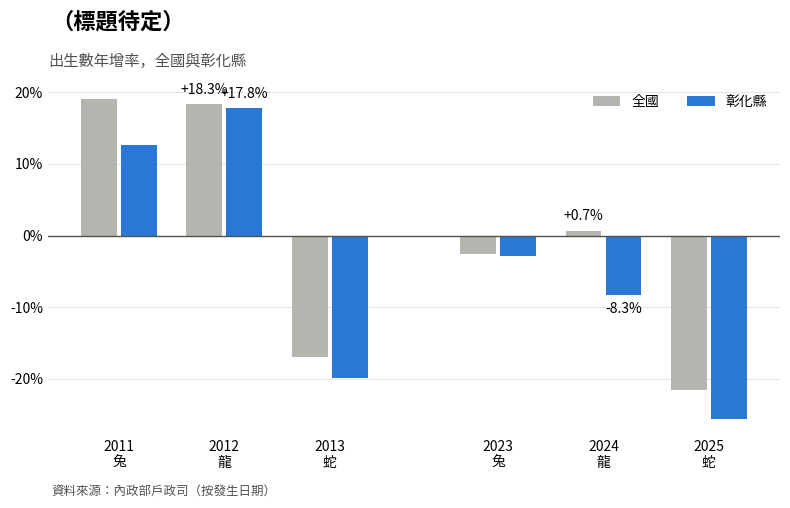

In [4]:
sub = annual[annual['county'].isin(['全國', '彰化縣'])].pivot(
    index='year', columns='county', values='births')
yoy = sub.pct_change().mul(100).round(1)
yrs = [2011, 2012, 2013, 2023, 2024, 2025]
print(yoy.loc[yrs])

x = [0, 1, 2, 3.6, 4.6, 5.6]
labels = ['2011\n兔', '2012\n龍', '2013\n蛇', '2023\n兔', '2024\n龍', '2025\n蛇']
w = 0.38

fig, ax = plt.subplots(figsize=(8, 5))
for i, (c, color) in enumerate([('全國', '#b5b4ae'), ('彰化縣', '#2a78d6')]):
    vals = yoy.loc[yrs, c]
    pos = [p + (i - 0.5) * w for p in x]
    ax.bar(pos, vals, width=w - 0.04, color=color, label=c)
    for p, v, y in zip(pos, vals, yrs):
        if y in (2012, 2024):
            ax.text(p, v + (1 if v >= 0 else -1), f'{v:+.1f}%', ha='center',
                    va='bottom' if v >= 0 else 'top', fontsize=10)

ax.axhline(0, color='#52514e', lw=1)
ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.grid(axis='y', color='#e5e4df', lw=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left', 'bottom']:
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.legend(frameon=False, loc='upper right', ncol=2)

fig.suptitle('（標題待定）', x=0.07, ha='left', fontsize=16, fontweight='bold')
ax.set_title('出生數年增率，全國與彰化縣', loc='left', fontsize=11, color='#52514e', pad=12)
fig.text(0.07, 0.01, '資料來源：內政部戶政司（按發生日期）', fontsize=9, color='#52514e')
fig.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(f'{base}/fig/02-changhua.png', dpi=200)
plt.show()

In [8]:
annual[annual['county'] == '全國'].set_index('year')['births'].diff().loc[[2012, 2024]]

,births
year,
2012,36251.0
2024,874.0
